# PCA on the tropical Pacific: finding ENSO

Principal component analysis (PCA) finds the directions in which a data set varies most, in order, and lets you keep only the first few. In climate science the same method is called EOF analysis, for empirical orthogonal functions. The two names describe one calculation: PCA is the statistics and machine learning term, EOF is the term in meteorology and oceanography. The spatial patterns are the EOFs, and the time series that say how strongly each pattern is present in each month are the principal components (PCs).

This tutorial applies it to 75 years of monthly sea surface temperature (SST) in the tropical Pacific. The question is whether PCA, which knows nothing about oceans, finds the El Niño Southern Oscillation (ENSO) on its own. ENSO is the largest year-to-year climate signal on the planet: the central and eastern Pacific warm by a degree or two for a year (El Niño) or cool (La Niña), and weather on every continent shifts with it.

The plan:

1. Load the data and look at one month.
2. Remove the seasonal cycle to get anomalies.
3. PCA in two dimensions, so the geometry is visible.
4. Build the Niño3.4 index by hand, as the thing to compare against.
5. Turn maps into a matrix, which is the step that makes PCA possible.
6. PCA on the raw SST, and why the first pattern is not interesting.
7. PCA on the anomalies: the EOFs, the PCs, and the comparison with Niño3.4.
8. How many components to keep, and what you lose when you drop the rest.
9. PCs as features for a forecast, with the Week 6 rules.

The concepts are in the [Dimensionality Reduction](../lectures_ML/UnsupervisedML/dimensionalityreduction.ipynb) lecture notes.

## 1. The data

NOAA's Extended Reconstructed SST, version 5, is a monthly global field on a 2 degree grid from 1854 to the present. We read it straight from NOAA's server with xarray. Nothing is downloaded until we ask for a region, so the first call is quick.

We keep the tropical Pacific, 30S to 30N and 120E to 300E (which is 60W), and the years 1950 to 2024. That is 900 months of 31 by 91 grid cells. Latitude in this file runs from north to south, so the slice goes from 30 to -30.

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

DATA = "https://psl.noaa.gov/thredds/dodsC/Datasets/noaa.ersst.v5/sst.mnmean.nc"
sst_all = xr.open_dataset(DATA)["sst"]

sst = sst_all.sel(lat=slice(30, -30), lon=slice(120, 300), time=slice("1950", "2024")).load()
print(sst.shape, "= (months, latitudes, longitudes)")
sst

(900, 31, 91) = (months, latitudes, longitudes)


<xarray.DataArray 'sst' (time: 900, lat: 31, lon: 91)> Size: 10MB
array([[[      nan, 13.930349, 15.72895 , ..., 21.944994, 21.843386,
         21.650068],
        [      nan, 17.226309, 18.995842, ..., 22.608603, 22.521927,
         22.366844],
        [19.101593, 20.176517, 21.857056, ..., 23.232748, 23.101763,
         22.965668],
        ...,
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan]],

       [[      nan, 12.613538, 14.582089, ..., 21.358143, 21.268549,
         21.13778 ],
        [      nan, 16.176378, 18.094715, ..., 22.237492, 22.181335,
         22.076412],
        [18.495483, 19.529808, 21.281982, ..., 23.001633, 22.905376,
         22.79012 ],
...
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan]],

       [[      nan, 16.498951, 18.199286, ..., 23.114628, 23.18844 ,
         23.214096],
        [      nan, 19.112827, 20.83363 , ..., 24.234886, 24.3491  ,
         24.407768],
        [20.698112, 21.702951, 23.379225, ..., 25.42383 , 25.517818,
         25.563478],
        ...,
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan]]], shape=(900, 31, 91), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 7kB 1950-01-01 1950-02-01 ... 2024-12-01
  * lat      (lat) float32 124B 30.0 28.0 26.0 24.0 ... -24.0 -26.0 -28.0 -30.0
  * lon      (lon) float32 364B 120.0 122.0 124.0 126.0 ... 296.0 298.0 300.0
Attributes:
    long_name:     Monthly Means of Sea Surface Temperature
    units:         degC
    var_desc:      Sea Surface Temperature
    level_desc:    Surface
    statistic:     Mean
    dataset:       NOAA Extended Reconstructed SST V5
    parent_stat:   Individual Values
    actual_range:  [-1.8     42.32636]
    valid_range:   [-1.8 45. ]
    _ChunkSizes:   [  1  89 180]

December 1997 was the peak of the strongest El Niño of the century. Plotting that month shows the problem we have to solve: the tropics are warm everywhere, the equatorial cold tongue off South America is a little weaker than usual, and the El Niño is not obvious to the eye. The white areas are land.

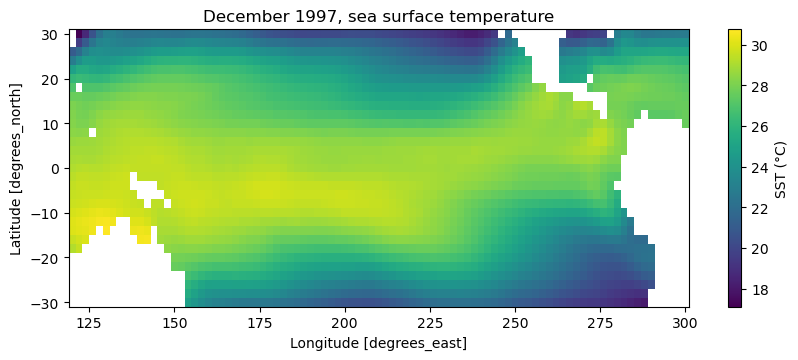

In [2]:
fig, ax = plt.subplots(figsize=(10, 3.6))
sst.sel(time="1997-12").squeeze().plot(ax=ax, cmap="viridis", cbar_kwargs={"label": "SST (°C)"})
ax.set_title("December 1997, sea surface temperature")
plt.show()

## 2. Anomalies: remove the seasonal cycle

Most of the month-to-month variation in SST is the seasons. To see ENSO we subtract, from every month, the long-term mean for that calendar month. The result is the anomaly: how much warmer or colder than a normal December, say, this December was. The climatology here is the 1950 to 2024 mean for each month.

`groupby("time.month")` collects all the Januaries, all the Februaries, and so on. Taking the mean gives twelve maps, and subtracting with the same grouping lines each month up with its own climatology.

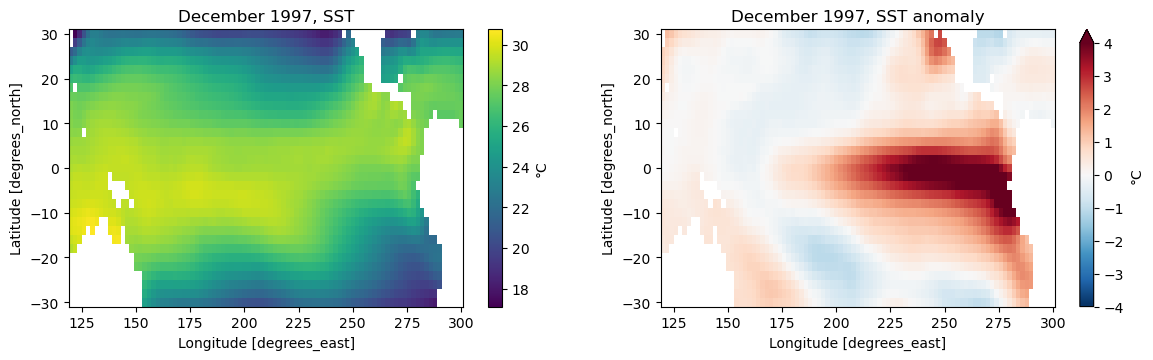

In [3]:
clim = sst.groupby("time.month").mean("time")       # twelve maps, one per calendar month
anom = sst.groupby("time.month") - clim             # anomaly: this month minus its climatology

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
sst.sel(time="1997-12").squeeze().plot(ax=axes[0], cmap="viridis", cbar_kwargs={"label": "°C"})
anom.sel(time="1997-12").squeeze().plot(ax=axes[1], cmap="RdBu_r", vmin=-4, vmax=4, cbar_kwargs={"label": "°C"})
axes[0].set_title("December 1997, SST")
axes[1].set_title("December 1997, SST anomaly")
plt.show()

Now the El Niño is unmistakable: a tongue of water 3 to 4 degrees warmer than normal along the equator from the dateline to South America, with cooler water to the west. PCA on the anomalies will have a chance of finding this pattern. PCA on the raw field would find the seasons first, which we will confirm in section 6.

## 3. PCA in two dimensions

Before the full field, two numbers per month. The Niño3 region (5S to 5N, 150W to 90W) is the eastern equatorial Pacific and Niño4 (160E to 150W) the central. Averaging the anomalies over each gives two time series, and each month is a point in the plane.

PCA finds the direction through the cloud with the largest spread, then the direction perpendicular to it. With two features there are exactly two components, so nothing is lost. The figure shows what they are.

principal directions (rows), as [Niño3, Niño4]:
[[ 0.82  0.57]
 [-0.57  0.82]]
fraction of variance explained: [0.895 0.105]


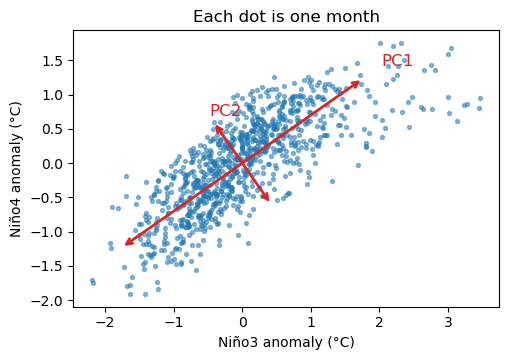

In [4]:
nino3 = anom.sel(lat=slice(5, -5), lon=slice(210, 270)).mean(["lat", "lon"])
nino4 = anom.sel(lat=slice(5, -5), lon=slice(160, 210)).mean(["lat", "lon"])
X2 = np.column_stack([nino3.values, nino4.values])     # 900 months by 2 features

pca2 = PCA(n_components=2).fit(X2)
print("principal directions (rows), as [Niño3, Niño4]:")
print(np.round(pca2.components_, 2))
print("fraction of variance explained:", np.round(pca2.explained_variance_ratio_, 3))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(X2[:, 0], X2[:, 1], s=8, alpha=0.5)
for i, (vec, var) in enumerate(zip(pca2.components_, pca2.explained_variance_)):
    arrow = vec * 2 * np.sqrt(var)
    ax.annotate("", xy=pca2.mean_ + arrow, xytext=pca2.mean_ - arrow, arrowprops=dict(arrowstyle="<->", color="C3", lw=2))
    ax.text(*(pca2.mean_ + arrow * 1.15), f"PC{i + 1}", color="C3", fontsize=12)
ax.set_xlabel("Niño3 anomaly (°C)"); ax.set_ylabel("Niño4 anomaly (°C)"); ax.set_aspect("equal")
ax.set_title("Each dot is one month")
plt.show()

The first direction is roughly (0.8, 0.6): both regions warm together or cool together. That is ENSO, and it carries about 90 percent of the variance. The second direction is the east-west contrast, east warm while the center is cool, with the remaining tenth. PCA has reduced two correlated series to one dominant one plus a smaller correction.

Everything that follows is this picture with 2,469 features instead of 2.

## 4. The Niño3.4 index

Before we let PCA loose on the whole field, we build the standard ENSO index by hand so we have something to compare the result to. The Niño3.4 index is the SST anomaly averaged over 5S to 5N, 170W to 120W, smoothed with a 5-month running mean, and divided by its standard deviation. Values above 1 are El Niño, below -1 La Niña.

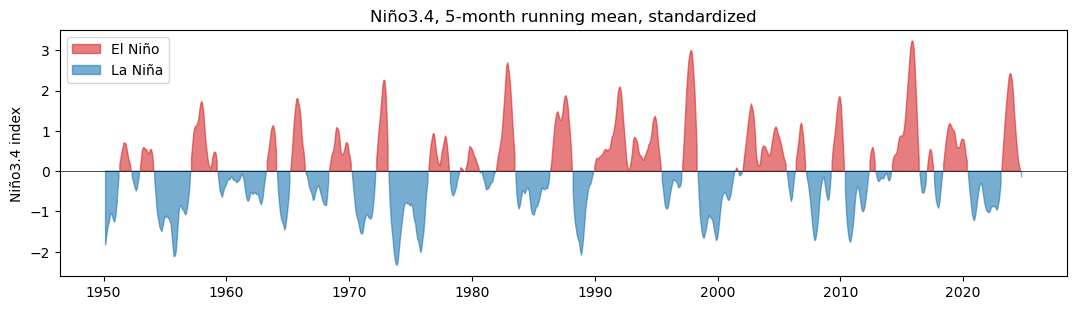

In [5]:
nino34 = anom.sel(lat=slice(5, -5), lon=slice(190, 240)).mean(["lat", "lon"])
nino34_index = nino34.rolling(time=5, center=True).mean()
nino34_index = nino34_index / nino34_index.std()

fig, ax = plt.subplots(figsize=(13, 3.2))
t = nino34_index.time.values
ax.fill_between(t, nino34_index, 0, where=nino34_index > 0, color="C3", alpha=0.6, label="El Niño")
ax.fill_between(t, nino34_index, 0, where=nino34_index < 0, color="C0", alpha=0.6, label="La Niña")
ax.axhline(0, color="k", lw=0.5); ax.set_ylabel("Niño3.4 index"); ax.legend(loc="upper left")
ax.set_title("Niño3.4, 5-month running mean, standardized")
plt.show()

The big El Niños stand out: 1972, 1982 to 83, 1997 to 98, 2015 to 16, 2023 to 24. This is one number per month, chosen by people who knew where ENSO lives. PCA has to find the same thing without being told where to look.

## 5. From maps to a matrix

scikit-learn wants a matrix with one row per sample and one column per feature. For us a sample is a month and a feature is a grid cell, so the 900 by 31 by 91 array becomes 900 by 2,821. Two details matter for climate fields:

**Land.** Grid cells on land are NaN, and PCA cannot take NaN. Filling them with zero works but adds 352 fake features that never vary. Dropping them is cleaner: we keep a boolean mask of ocean cells, do PCA on the ocean columns only, and use the mask to put results back on the map.

**Area weights.** A 2 degree cell at 30N covers less area than one on the equator. Without a weight, PCA counts the high-latitude cells as much as the tropical ones. The standard fix is to multiply each cell by the square root of the cosine of its latitude, so that variance, which is squared, is weighted by cosine, which is area. Over 30S to 30N the correction is small, but the habit matters when the domain is larger.

One thing we do not do is standardize each grid cell to unit variance, which is what `StandardScaler` would do. That would make a quiet cell in the western Pacific count as much as a cell in the cold tongue that swings by 4 degrees, and it would erase the thing we are looking for. For a single field in one unit, center but do not scale.

In [6]:
weight = np.sqrt(np.cos(np.deg2rad(anom.lat)))          # area weight, one value per latitude

def to_matrix(field):
    # (months, lat, lon) DataArray -> (months, ocean cells) array, plus the ocean mask
    flat = (field * weight).values.reshape(field.shape[0], -1)
    ocean = ~np.isnan(flat[0])
    return flat[:, ocean], ocean

def to_map(vector, ocean):
    # one row of the matrix back onto the grid, NaN over land, as a DataArray with coordinates
    full = np.full(ocean.size, np.nan)
    full[ocean] = vector
    return xr.DataArray(full.reshape(anom.shape[1:]), coords={"lat": anom.lat, "lon": anom.lon}) / weight

X_anom, ocean = to_matrix(anom)
print("matrix:", X_anom.shape, "= (months, ocean cells);", (~ocean).sum(), "land cells dropped")

matrix: (900, 2469) = (months, ocean cells); 352 land cells dropped


## 6. PCA on the raw field: the seasons win

What happens if we skip section 2 and give PCA the raw SST? The same reshaping, then `PCA` with ten components. The first pattern explains three quarters of the variance, and its time series is a clean annual wave. PCA has found the seasonal cycle, because the seasons are the largest source of variance in the raw field. True, and useless, which is why climate work almost always starts from anomalies.

variance explained by the first three patterns of raw SST: [0.768 0.098 0.036]


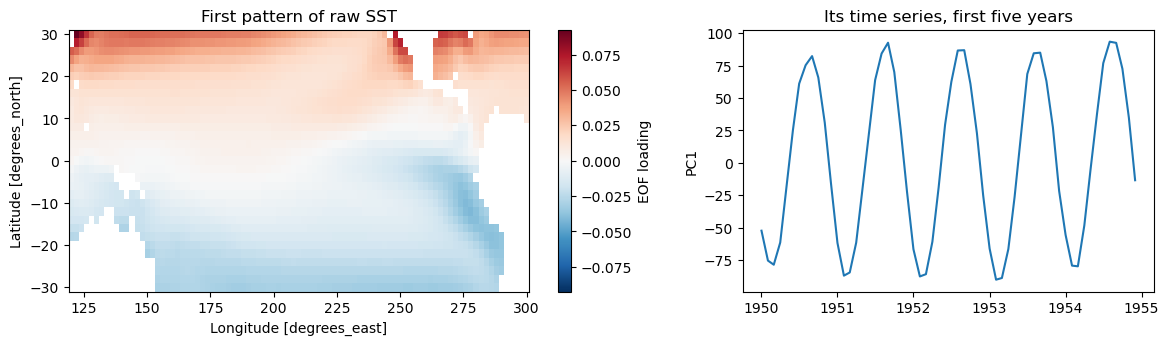

In [7]:
X_raw, _ = to_matrix(sst)
pca_raw = PCA(n_components=10).fit(X_raw)
pcs_raw = pca_raw.transform(X_raw)
print("variance explained by the first three patterns of raw SST:", np.round(pca_raw.explained_variance_ratio_[:3], 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), gridspec_kw={"width_ratios": [1.4, 1]})
to_map(pca_raw.components_[0], ocean).plot(ax=axes[0], cmap="RdBu_r", cbar_kwargs={"label": "EOF loading"})
axes[0].set_title("First pattern of raw SST")
axes[1].plot(sst.time[:60], pcs_raw[:60, 0])
axes[1].set_title("Its time series, first five years"); axes[1].set_ylabel("PC1")
plt.show()

## 7. PCA on the anomalies

Now the real thing. We fit PCA on the anomaly matrix and ask for 50 components, which is plenty, and look at how the variance is spread.

variance explained, first five: [0.401 0.151 0.081 0.046 0.036]


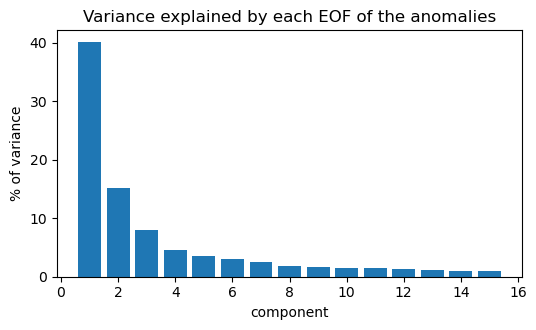

In [8]:
pca = PCA(n_components=50).fit(X_anom)
pcs = pca.transform(X_anom)                 # 900 months by 50: the principal components
eofs = pca.components_                      # 50 by 2,469: the spatial patterns

evr = pca.explained_variance_ratio_
print("variance explained, first five:", np.round(evr[:5], 3))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(np.arange(1, 16), evr[:15] * 100)
ax.set_xlabel("component"); ax.set_ylabel("% of variance"); ax.set_title("Variance explained by each EOF of the anomalies")
plt.show()

The first component carries 40 percent of the variance, the second 15, and then a long tail. One pattern dominates, and we can look at it.

Two notes before we do. The sign of an EOF is arbitrary: the pattern and its negative describe the same variance, and scikit-learn picks whichever comes out of the computation. We flip EOF1 so that it is positive in the Niño3.4 region, which makes a positive PC1 mean El Niño. And we standardize PC1 so that it is on the same scale as the Niño3.4 index.

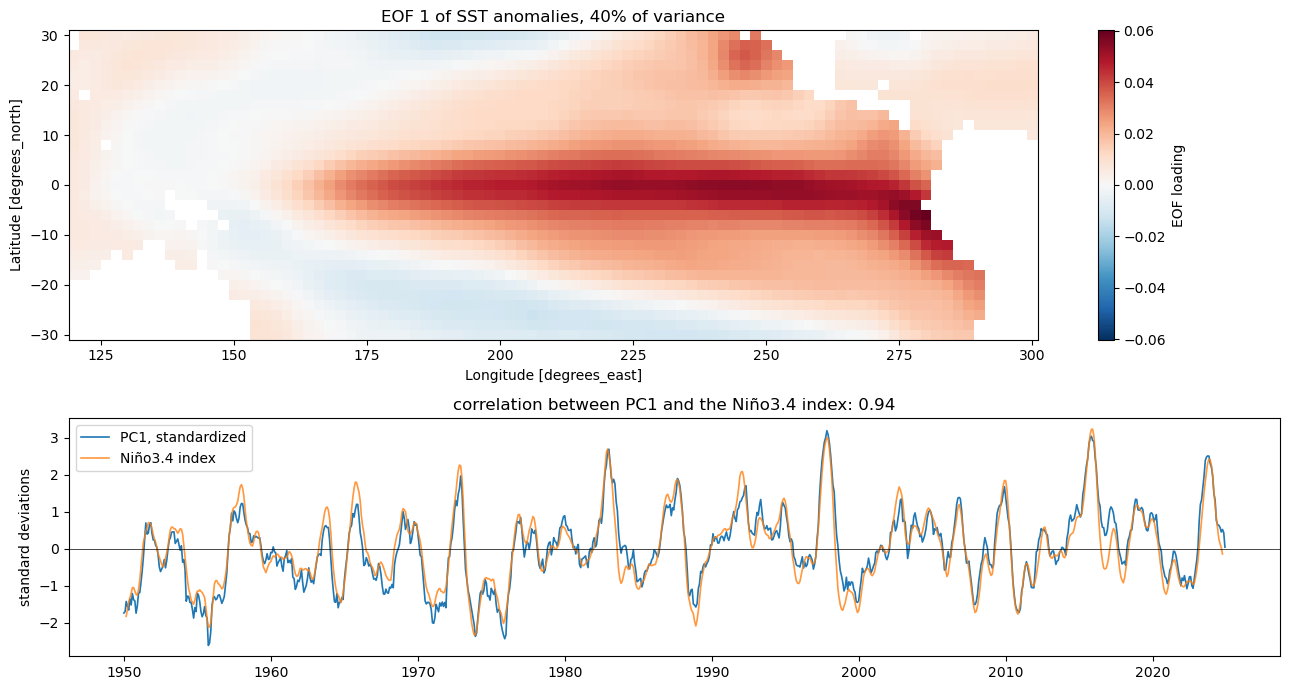

In [9]:
eof1_map = to_map(eofs[0], ocean)
sign = np.sign(float(eof1_map.sel(lat=slice(5, -5), lon=slice(190, 240)).mean()))
eof1_map = eof1_map * sign
pc1 = pcs[:, 0] * sign / pcs[:, 0].std()

fig, axes = plt.subplots(2, 1, figsize=(13, 7), gridspec_kw={"height_ratios": [1.3, 1]})
eof1_map.plot(ax=axes[0], cmap="RdBu_r", cbar_kwargs={"label": "EOF loading"})
axes[0].set_title(f"EOF 1 of SST anomalies, {evr[0] * 100:.0f}% of variance")
axes[1].plot(anom.time, pc1, label="PC1, standardized", lw=1.2)
axes[1].plot(nino34_index.time, nino34_index, label="Niño3.4 index", lw=1.2, alpha=0.8)
axes[1].axhline(0, color="k", lw=0.5); axes[1].legend(loc="upper left"); axes[1].set_ylabel("standard deviations")
ok = ~np.isnan(nino34_index.values)
axes[1].set_title(f"correlation between PC1 and the Niño3.4 index: {np.corrcoef(pc1[ok], nino34_index.values[ok])[0, 1]:.2f}")
plt.tight_layout(); plt.show()

EOF 1 is the El Niño pattern: warm along the equator from the dateline to South America, strongest in the east, with weaker cooling to the northwest and southwest. Nobody told PCA where the Niño3.4 box is. It found the pattern because that pattern is where the variance is, and its time series tracks the hand-built index with a correlation of 0.94. The index is smoother only because of its 5-month running mean.

The second EOF is worth a look too, because it is not what most people expect. It is positive almost everywhere except along the equator, and its time series climbs steadily from 1950 to today: the warming trend. We computed anomalies against a single 75-year climatology, so early decades come out cold and recent ones warm, and PCA reports that as the second-largest source of variance. The cold tongue is the exception because it has warmed less than the water around it. If ENSO alone were the goal, the next step would be to detrend before PCA, the same way we removed the seasons. Leaving it in shows what the method does: it ranks whatever varies, whether or not you asked for it.

A caution that applies to every EOF after the first: it is orthogonal to the ones before it by construction, which means its time series is uncorrelated with PC1 over the record, not that the ocean has a separate physical mode with this shape.

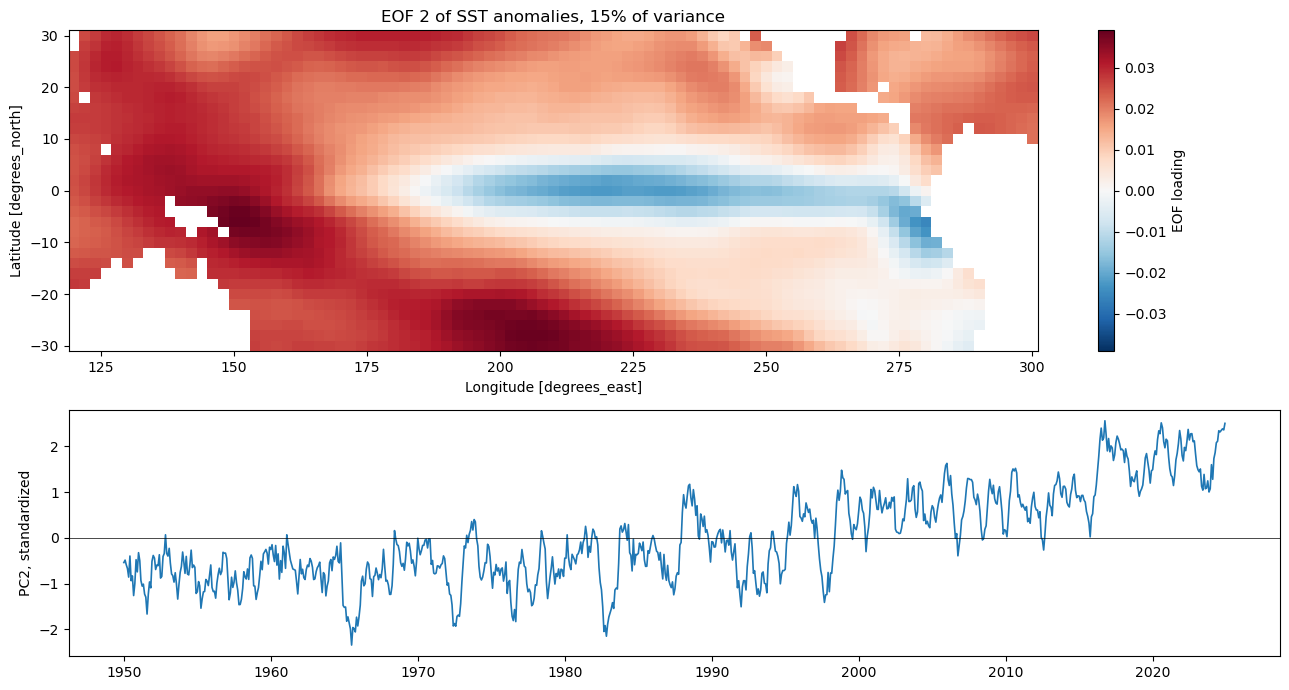

In [10]:
eof2_map = to_map(eofs[1], ocean)
pc2 = pcs[:, 1] / pcs[:, 1].std()

fig, axes = plt.subplots(2, 1, figsize=(13, 7), gridspec_kw={"height_ratios": [1.3, 1]})
eof2_map.plot(ax=axes[0], cmap="RdBu_r", cbar_kwargs={"label": "EOF loading"})
axes[0].set_title(f"EOF 2 of SST anomalies, {evr[1] * 100:.0f}% of variance")
axes[1].plot(anom.time, pc2, lw=1.2); axes[1].axhline(0, color="k", lw=0.5); axes[1].set_ylabel("PC2, standardized")
plt.tight_layout(); plt.show()

## 8. How many components to keep

PCA returns as many components as you ask for, up to the number of features. The usual question is how many are needed, and the usual answer is a cumulative variance curve: keep enough components to retain some fraction of the total, often 90 or 95 percent. `PCA(n_components=0.9)` does this automatically.

For the Pacific anomalies the curve rises fast and then flattens. The first component is 40 percent, the first ten are 82, and 90 percent needs 18. That is 2,469 numbers per month compressed to 18, with a tenth of the variance lost.

components for 90% of the variance: 18


PCA(n_components=0.9) keeps: 18


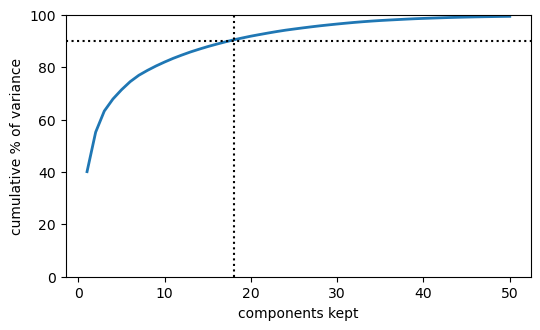

In [11]:
cum = np.cumsum(evr)
k90 = int(np.argmax(cum >= 0.90)) + 1
print("components for 90% of the variance:", k90)
print("PCA(n_components=0.9) keeps:", PCA(n_components=0.9).fit(X_anom).n_components_)

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(np.arange(1, 51), cum * 100, lw=2)
ax.axhline(90, ls=":", color="k"); ax.axvline(k90, ls=":", color="k")
ax.set_xlabel("components kept"); ax.set_ylabel("cumulative % of variance"); ax.set_ylim(0, 100)
plt.show()

What does losing a tenth of the variance look like? The matrix can be rebuilt from the first k components: multiply each PC by its EOF and add them up. This is `inverse_transform`, and it is the climate version of compressing an image. We rebuild December 1997 from 1, 3, 10, and 50 components and put the truth beside them.

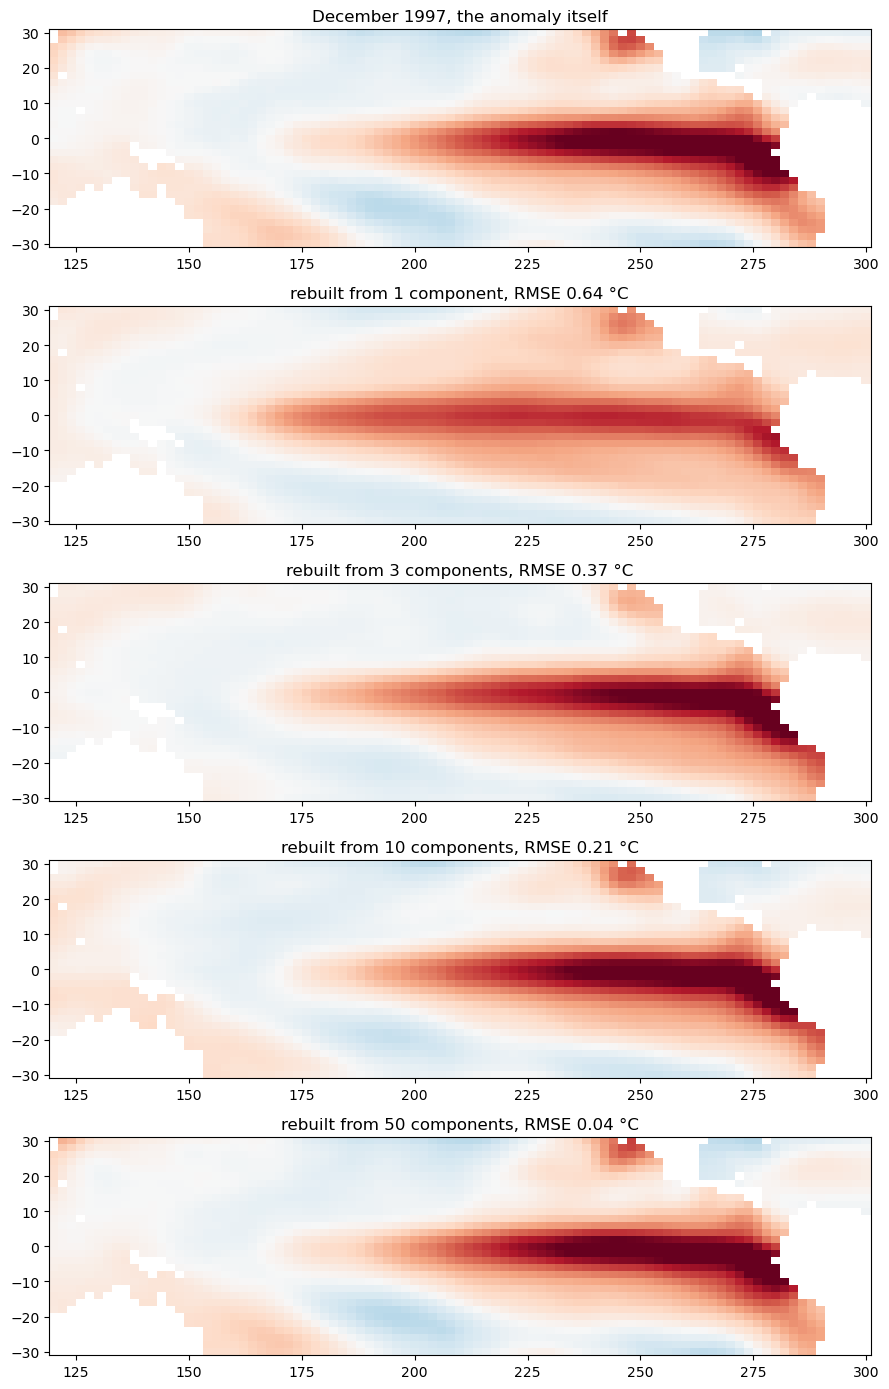

In [12]:
i = int(np.where(anom.time.values.astype("datetime64[M]") == np.datetime64("1997-12"))[0][0])

fig, axes = plt.subplots(5, 1, figsize=(9, 14))
to_map(X_anom[i], ocean).plot(ax=axes[0], cmap="RdBu_r", vmin=-4, vmax=4, add_colorbar=False)
axes[0].set_title("December 1997, the anomaly itself")
for ax, k in zip(axes[1:], [1, 3, 10, 50]):
    rebuilt = pcs[i, :k] @ eofs[:k] + pca.mean_               # inverse transform with k components
    err = np.sqrt(np.mean((rebuilt - X_anom[i]) ** 2))
    to_map(rebuilt, ocean).plot(ax=ax, cmap="RdBu_r", vmin=-4, vmax=4, add_colorbar=False)
    ax.set_title(f"rebuilt from {k} component{'s' if k > 1 else ''}, RMSE {err:.2f} °C")
for ax in axes: ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

One component gives the shape of the event and nothing else. Three fix the structure in the east. Ten are close, with a residual of 0.2 degrees, and fifty are indistinguishable from the original. For a data set where the first pattern is this dominant, a handful of numbers per month capture most of what the 2,469 grid cells say.

## 9. PCs as features: a forecast with the Week 6 rules

The practical reason to do this in a machine learning course: the PCs are a compact, uncorrelated description of the state of the Pacific, and that makes them good inputs to a model. A regression on 2,469 grid cells with 900 months of data would overfit badly. A regression on 10 PCs will not.

The test: predict the Niño3.4 anomaly some months ahead from the first 10 PCs today. The rules from last week apply. The split is in time, training on 1950 to 2000 and testing on 2001 to 2024, because a shuffled split would train on the future. And every score sits next to two baselines: persistence, which predicts that the anomaly stays where it is, and climatology, which predicts zero anomaly.

In [13]:
from sklearn.linear_model import Ridge

y = nino34.values                      # unsmoothed Niño3.4 anomaly, one per month
year = anom.time.dt.year.values
rmse = lambda truth, pred: np.sqrt(np.mean((truth - pred) ** 2))

print("lead   ridge on 10 PCs   persistence   climatology")
for lead in [3, 6, 9, 12]:
    X_now, y_later = pcs[:-lead, :10], y[lead:]          # PCs at month t, index at month t + lead
    persist = y[:-lead]
    train, test = year[lead:] <= 2000, year[lead:] > 2000
    model = Ridge(alpha=1.0).fit(X_now[train], y_later[train])
    print(f"{lead:>3}    {rmse(y_later[test], model.predict(X_now[test])):.2f}             "
          f"{rmse(y_later[test], persist[test]):.2f}          {rmse(y_later[test], 0 * y_later[test]):.2f}")

lead   ridge on 10 PCs   persistence   climatology
  3    0.54             0.59          0.85
  6    0.74             0.96          0.85
  9    0.81             1.16          0.85
 12    0.88             1.22          0.85


At a 3-month lead, persistence is a strong baseline and the model beats it by a little. At 6 months and beyond, persistence is worse than predicting nothing, which is the well-known spring predictability barrier: an anomaly in March tells you little about September. The ridge on 10 PCs still beats both baselines at every lead, because the PCs carry the spatial structure of the event, where the warm water is and what is building to the west, and not only its current amplitude. Part of its edge is also PC2, the trend, which lets it know that the test years are warmer than the training years.

This is the pattern to remember. PCA is unsupervised and never saw the target. It turned a field into a few numbers, and a supervised model built on those numbers did something a model on the raw field could not. A neural network could learn the same compression, and later weeks build that, but 10 PCs and a linear model is often the honest first attempt.

## Checklist

- **PCA and EOF analysis are the same calculation.** Center the data, factor it, keep the leading directions. The patterns are EOFs, the time series are PCs.
- **Remove what you already understand first.** On raw SST the first component is the seasonal cycle, and on anomalies the second is the warming trend. PCA ranks whatever varies, so take out the known signals before asking what is left.
- **Shape the matrix with care.** Samples by features, here months by grid cells. Drop land rather than filling it, weight by the square root of cosine of latitude, and do not standardize cells of a single field.
- **The sign of an EOF is arbitrary.** Choose it so that the time series means something, and say which way you chose.
- **Orthogonal is not the same as physical.** Each EOF is uncorrelated with the ones before it because the method demands it, not because the ocean has independent modes of that shape.
- **How many to keep is a choice.** Use the cumulative variance curve, and look at what the reconstruction loses.
- **PCs make good features.** Uncorrelated, few, and ranked by variance. With them, the Week 6 rules still apply: split in time, compare to a baseline, report the error.